# Political Embedder Small — t-SNE Analysis

This notebook evaluates the latent embedding space of the fine-tuned `political-embedder-small` (`sentence-transformers/all-mpnet-base-v2`) using t-Distributed Stochastic Neighbor Embedding (t-SNE).


In [1]:
import sys
from pathlib import Path

ROOT = Path("../")
sys.path.insert(0, str(ROOT / "src"))

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sentence_transformers import SentenceTransformer

from config import MODEL_DIR, OUT_DIR, DATA_DIR

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120


## Sample embeddings


In [2]:
context_path = OUT_DIR / "political_embeddings.parquet"
df = pl.read_parquet(context_path)

print(f"Sampled {len(df):,} videos.")
df.head(5)


Sampled 111,967 videos.


,id,channel,title,slant,political_saliency,embedding
0,oWZEHs5Covo,Vital Information,The narrative is crumbling.,-0.230769,1.0,"[0.03433551266789436, 0.07947756350040436, 0.024616172537207603, 0.011674759909510612, -0.015551121905446053, 0.006407636683434248, -0.05829109624028206, -0.03607667610049248, -0.02773018553853035, 0.04011427238583565, 0.05554493889212608, 0.06279850006103516, 0.04138145595788956, 0.05089029297232628, 0.026430482044816017, -0.07268355786800385, 0.019990520551800728, 0.04197971522808075, 0.03267950192093849, 0.003140456508845091, 0.021239520981907845, 0.004560369532555342, -0.03624512627720833, 0.032768614590168, -0.04538856819272041, 0.0010239477269351482, 0.05229383707046509, -0.015212585218250751, 0.03903033211827278, -0.029128555208444595, 0.02993413805961609, -0.046496350318193436, 0.005363989621400833, 0.03587964177131653, 0.008349405601620674, 0.0009401551214978099, 0.034652285277843475, 0.029332324862480164, -0.07174064218997955, -0.008485715836286545, -0.019516276195645332, -0.039617303758859634, -0.03304796665906906, -3.006870610988699e-05, -0.028739599511027336, 0.03970424085855484, 0.011845163069665432, 0.021977799013257027, 0.014096635393798351, -0.011866198852658272, -0.01877940073609352, -0.02220916375517845, 0.03574434295296669, -0.009211369790136814, 0.059496138244867325, -6.144487269921228e-05, -0.020572597160935402, 0.04639082029461861, 0.05449807271361351, -0.03803956136107445, 0.0056511289440095425, 0.07238788157701492, -0.020366935059428215, 0.023701371625065804, 0.002936137141659856, 0.059243280440568924, 0.04083757475018501, 0.02017793245613575, 0.021378882229328156, -0.010738285258412361, 0.14421755075454712, 0.0523548498749733, 0.003761898260563612, 0.05886223539710045, -0.019685588777065277, -0.06149784475564957, -0.0469609871506691, 0.012975573539733887, -0.014669861644506454, -0.03815159574151039, -0.012180168181657791, 0.06999339163303375, 0.008920377120375633, 0.007908950559794903, 0.05165538191795349, 0.01737867295742035, -0.013633280992507935, -0.007687083911150694, -0.004887837916612625, 0.028126856312155724, 0.026531295850872993, -0.029053732752799988, -0.05637365207076073, -0.016606096178293228, 0.02247696928679943, -0.005703439004719257, -0.016965167596936226, 0.01108881738036871, 0.05524064600467682, -0.027255753055214882, ...]"
1,_XOerG5R290,Dr. John Campbell,South Africa Omicron,0.157890,0.5,"[0.03001725673675537, 0.07357118278741837, 0.012730381451547146, 0.014381743036210537, 0.013584095053374767, -0.005965301766991615, -0.06594894081354141, -0.03756020590662956, 0.0037006984930485487, 0.04383327066898346, 0.020710894837975502, 0.09271746128797531, 0.05686550959944725, 0.031625233590602875, 0.040597520768642426, -0.09176656603813171, 0.03827299550175667, 0.03736373782157898, 0.00991594698280096, 0.008038261905312538, 0.005534775089472532, 0.0045097763650119305, -0.03544151410460472, 0.016425227746367455, -0.014492640271782875, -0.0010796331334859133, 0.04359298571944237, -0.020136786624789238, 0.03682761266827583, -0.03304057568311691, 0.033676888793706894, -0.06724788248538971, 0.013701457530260086, 0.006692919414490461, 0.008805266581475735, -0.004575810860842466, 0.043113019317388535, 0.024039380252361298, -0.050295669585466385, -0.00976549182087183, -0.02145770564675331, -0.04963959753513336, -0.028534427285194397, 0.005917449481785297, -0.03564249724149704, 0.054504793137311935, 0.0022715318482369184, -0.0072293453849852085, 0.0022991818841546774, 0.0026897445786744356, -0.02509300410747528, -0.038782455027103424, 0.04049200564622879, -0.015436084009706974, 0.04237181320786476, -0.0452348068356514, -0.020827142521739006, 0.04061572253704071, 0.06964142620563507, -0.032144926488399506, -0.01393518690019846, 0.06095028668642044, -0.032970547676086426, 0.03238610178232193, 0.022606711834669113, 0.05735392868518829, 0.034267179667949677, 0.002181506948545575, -0.009559723548591137, 0.007662361487746239, 0.13820476830005646, 0.03630456328392029, 0.0070664635859

## Run t-SNE


In [3]:
# Sample 10,000 embeddings for t-SNE projection
SEED = 42
plot_df = df.sample(10_000, seed=SEED).to_pandas().copy()

embeddings = np.vstack(plot_df["embedding"].to_numpy())
tsne = TSNE(n_components=1, random_state=SEED, perplexity=30, max_iter=1000, n_jobs=-1)
coords_1d = tsne.fit_transform(embeddings).flatten()

# Check orientation: orient so that positive values align with conservative slant (matching PCA)
from scipy.stats import pearsonr
clean_mask = ~plot_df["slant"].isna()
raw_corr, _ = pearsonr(coords_1d[clean_mask], plot_df.loc[clean_mask, "slant"])
if raw_corr < 0:
    coords_1d = -coords_1d

plot_df["tsne_1"] = coords_1d
print(f"t-SNE 1D projection complete. Correlation with slant: {abs(raw_corr):.4f}")
plot_df.head(3)


t-SNE 1D projection complete. Correlation with slant: 0.6241


,id,channel,title,slant,political_saliency,embedding,tsne_1
0,STXwmr01J0o,Pathe,EIFFEL - Official Trailer,-0.81818,0.5,"[0.0469999797642231, 0.08299597352743149, 0.018246261402964592, 0.035787295550107956, -0.015557164326310158, -0.0028350299689918756, -0.06217390298843384, -0.04207540303468704, -0.012185455299913883, 0.03448908403515816, 0.023799818009138107, 0.05646888539195061, 0.030673814937472343, 0.03560435026884079, 0.03496735915541649, -0.06800853461027145, -0.0005216270801611245, 0.05903267487883568, -0.013242366723716259, 0.012272397987544537, 0.019049502909183502, -0.003510551294311881, -0.03771507740020752, 0.02778502367436886, -0.04170253872871399, -0.014269908890128136, 0.02531450428068638, 0.007657316979020834, 0.027337349951267242, -0.017058759927749634, 0.017848899587988853, -0.050150834023952484, 0.002225652802735567, 0.018242506310343742, 0.008530989289283752, -0.01205169502645731, 0.04906638711690903, -0.007205274887382984, -0.03166865557432175, -0.012141968123614788, -0.015316636301577091, -0.012460061348974705, -0.042742278426885605, -0.02869187667965889, -0.008343367837369442, 0.0670485720038414, 0.01089776773005724, 0.0018782768165692687, 0.009856102988123894, -0.00572171900421381, -0.02760957181453705, -0.041292160749435425, 0.01818135194480419, -0.02803262136876583, 0.05801692605018616, -0.023249562829732895, -0.01571403257548809, 0.0027466914616525173, 0.06191087141633034, -0.02247592620551586, -0.019251050427556038, 0.027294477447867393, -0.0030384238343685865, 0.040370408445596695, 0.04301893338561058, 0.03683963045477867, 0.0432065948843956, 0.004442114848643541, -0.014055175706744194, -0.001526329666376114, 0.11600948125123978, 0.050744567066431046, 0.0015007451875135303, 0.05176495760679245, -0.019944937899708748, -0.06364186108112335, -0.05367002636194229, -0.008280194364488125, 0.007993411272764206, -0.0367882214486599, -0.011213378049433231, 0.04650897532701492, 0.01994888111948967, 0.005244516301900148, 0.03469303995370865, 0.027969403192400932, -0.011164977215230465, -0.003591810120269656, 0.020719392225146294, 0.044322140514850616, 0.015773314982652664, -0.027837663888931274, -0.055657461285591125, -0.02536948025226593, 0.023063722997903824, -0.000729151361156255, -0.005744855385273695, 0.0013504567323252559, 0.04425102099776268, -0.001970522804185748, ...]",-29.512642
1,r-cW1ct5PMA,Gerd Leonhard,The #future is #mindboggling - Futurist #KeynoteSpeaker Gerd Leonhard's favorite word (apparently),-0.76000,0.5,"[0.04098751023411751, 0.05855567380785942, 0.021227847784757614, 0.027537032961845398, 0.008061123080551624, -0.010844296775758266, -0.06201793625950813, -0.03650052845478058, 0.015942616388201714, 0.044040899723768234, 0.027273690328001976, 0.06394804269075394, 0.03292050212621689, 0.04952036589384079, 0.043591223657131195, -0.08849329501390457, 0.021169621497392654, 0.035760343074798584, 0.011070933192968369, -0.0022482669446617365, 0.027469802647829056, -0.007999268360435963, -0.03582417964935303, 0.032305628061294556, -0.03724382072687149, -0.007517021149396896, 0.04726603999733925, 0.0013659787364304066, 0.03776806220412254, 0.006781957112252712, 0.042067017406225204, -0.05744769051671028, -0.002885004971176386, 0.02873407118022442, 0.008313522674143314, -0.021041158586740494, 0.02511756867170334, 0.020831484347581863, -0.03343672305345535, 0.012522286735475063, -0.015958918258547783, -0.027350900694727898, -0.03980512544512749, 0.0033650887198746204, -0.031778451055288315, 0.07117725163698196, 0.02127639204263687, 0.0043699173256754875, 0.0106031009927392, -0.007374501321464777, -0.02424449846148491, -0.033600784838199615, 0.03905039280653, -0.016606317833065987, 0.06017144024372101, -0.03130701556801796, -0.026743216440081596, 0.03104248270392418, 0.06386055052280426, -0.029296061024069786, -0.013262124732136726, 0.0493968166410923, -0.021297860890626907, 0.03694288432598114, 0.03003382682800293, 0.041360314935445786, 0.027655161917209625, 0.005988315679132938, -0.001711526885628

## Visualizations


In [4]:
# Sample 10,000 and attach t-SNE coordinates
plot_df_sample = plot_df.copy()

plot_df_sample.head()


,id,channel,title,slant,political_saliency,embedding,tsne_1
0,STXwmr01J0o,Pathe,EIFFEL - Official Trailer,-0.818180,0.5,"[0.0469999797642231, 0.08299597352743149, 0.018246261402964592, 0.035787295550107956, -0.015557164326310158, -0.0028350299689918756, -0.06217390298843384, -0.04207540303468704, -0.012185455299913883, 0.03448908403515816, 0.023799818009138107, 0.05646888539195061, 0.030673814937472343, 0.03560435026884079, 0.03496735915541649, -0.06800853461027145, -0.0005216270801611245, 0.05903267487883568, -0.013242366723716259, 0.012272397987544537, 0.019049502909183502, -0.003510551294311881, -0.03771507740020752, 0.02778502367436886, -0.04170253872871399, -0.014269908890128136, 0.02531450428068638, 0.007657316979020834, 0.027337349951267242, -0.017058759927749634, 0.017848899587988853, -0.050150834023952484, 0.002225652802735567, 0.018242506310343742, 0.008530989289283752, -0.01205169502645731, 0.04906638711690903, -0.007205274887382984, -0.03166865557432175, -0.012141968123614788, -0.015316636301577091, -0.012460061348974705, -0.042742278426885605, -0.02869187667965889, -0.008343367837369442, 0.0670485720038414, 0.01089776773005724, 0.0018782768165692687, 0.009856102988123894, -0.00572171900421381, -0.02760957181453705, -0.041292160749435425, 0.01818135194480419, -0.02803262136876583, 0.05801692605018616, -0.023249562829732895, -0.01571403257548809, 0.0027466914616525173, 0.06191087141633034, -0.02247592620551586, -0.019251050427556038, 0.027294477447867393, -0.0030384238343685865, 0.040370408445596695, 0.04301893338561058, 0.03683963045477867, 0.0432065948843956, 0.004442114848643541, -0.014055175706744194, -0.001526329666376114, 0.11600948125123978, 0.050744567066431046, 0.0015007451875135303, 0.05176495760679245, -0.019944937899708748, -0.06364186108112335, -0.05367002636194229, -0.008280194364488125, 0.007993411272764206, -0.0367882214486599, -0.011213378049433231, 0.04650897532701492, 0.01994888111948967, 0.005244516301900148, 0.03469303995370865, 0.027969403192400932, -0.011164977215230465, -0.003591810120269656, 0.020719392225146294, 0.044322140514850616, 0.015773314982652664, -0.027837663888931274, -0.055657461285591125, -0.02536948025226593, 0.023063722997903824, -0.000729151361156255, -0.005744855385273695, 0.0013504567323252559, 0.04425102099776268, -0.001970522804185748, ...]",-29.512642
1,r-cW1ct5PMA,Gerd Leonhard,The #future is #mindboggling - Futurist #KeynoteSpeaker Gerd Leonhard's favorite word (apparently),-0.760000,0.5,"[0.04098751023411751, 0.05855567380785942, 0.021227847784757614, 0.027537032961845398, 0.008061123080551624, -0.010844296775758266, -0.06201793625950813, -0.03650052845478058, 0.015942616388201714, 0.044040899723768234, 0.027273690328001976, 0.06394804269075394, 0.03292050212621689, 0.04952036589384079, 0.043591223657131195, -0.08849329501390457, 0.021169621497392654, 0.035760343074798584, 0.011070933192968369, -0.0022482669446617365, 0.027469802647829056, -0.007999268360435963, -0.03582417964935303, 0.032305628061294556, -0.03724382072687149, -0.007517021149396896, 0.04726603999733925, 0.0013659787364304066, 0.03776806220412254, 0.006781957112252712, 0.042067017406225204, -0.05744769051671028, -0.002885004971176386, 0.02873407118022442, 0.008313522674143314, -0.021041158586740494, 0.02511756867170334, 0.020831484347581863, -0.03343672305345535, 0.012522286735475063, -0.015958918258547783, -0.027350900694727898, -0.03980512544512749, 0.0033650887198746204, -0.031778451055288315, 0.07117725163698196, 0.02127639204263687, 0.0043699173256754875, 0.0106031009927392, -0.007374501321464777, -0.02424449846148491, -0.033600784838199615, 0.03905039280653, -0.016606317833065987, 0.06017144024372101, -0.03130701556801796, -0.026743216440081596, 0.03104248270392418, 0.06386055052280426, -0.029296061024069786, -0.013262124732136726, 0.0493968166410923, -0.021297860890626907, 0.03694288432598114, 0.03003382682800293, 0.041360314935445786, 0.027655161917209625, 0.005988315679132938, -0.0017115268856

### Plot A: Embedding Projection Colored by Political Slant
* Blue = Left / Liberal (-1.0)
* Red = Right / Conservative (+1.0)


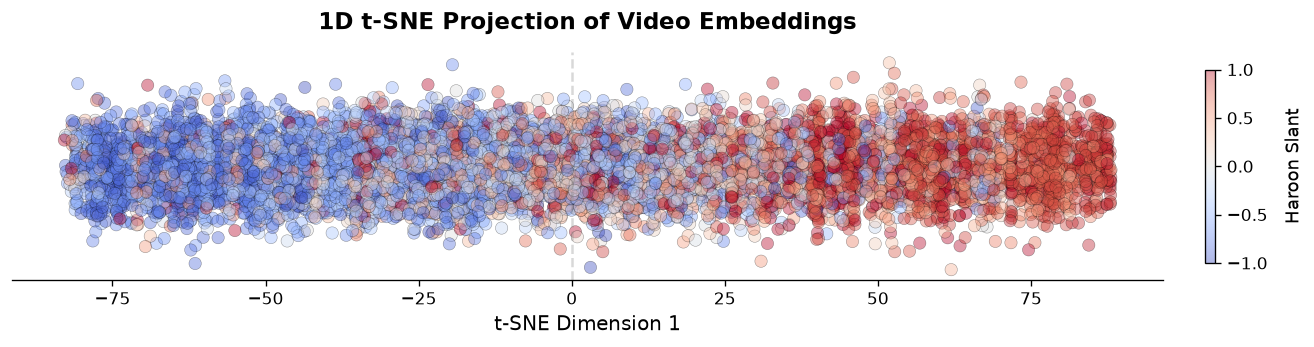

In [5]:
# 1. Reduce the height of the figure for a 1D layout (e.g., 12x3 instead of 12x8)
fig, ax = plt.subplots(figsize=(12, 3))

# 2. Create a dummy y-axis jitter
y_vals = np.random.normal(loc=0, scale=0.02, size=len(plot_df_sample))

scatter = ax.scatter(
    plot_df_sample["tsne_1"],
    y_vals,
    c=plot_df_sample["slant"],
    cmap="coolwarm",
    alpha=0.4,
    edgecolors="black",
    linewidth=0.3,
    s=55
)

cbar = plt.colorbar(scatter, ax=ax, shrink=0.85, pad=0.03)
cbar.set_label("Haroon Slant", fontsize=11, labelpad=10)

ax.set_title(
    "1D t-SNE Projection of Video Embeddings",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("t-SNE Dimension 1", fontsize=12)

# 3. Clean up the plot by hiding the meaningless y-axis and top/side borders
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

# Keep the vertical origin line to show the center of the t-SNE space
ax.axvline(0, color="grey", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


### Plot C: Highlight Top News / Commentary Channels
Check how specific prominent media channels distribute across the learned latent space.


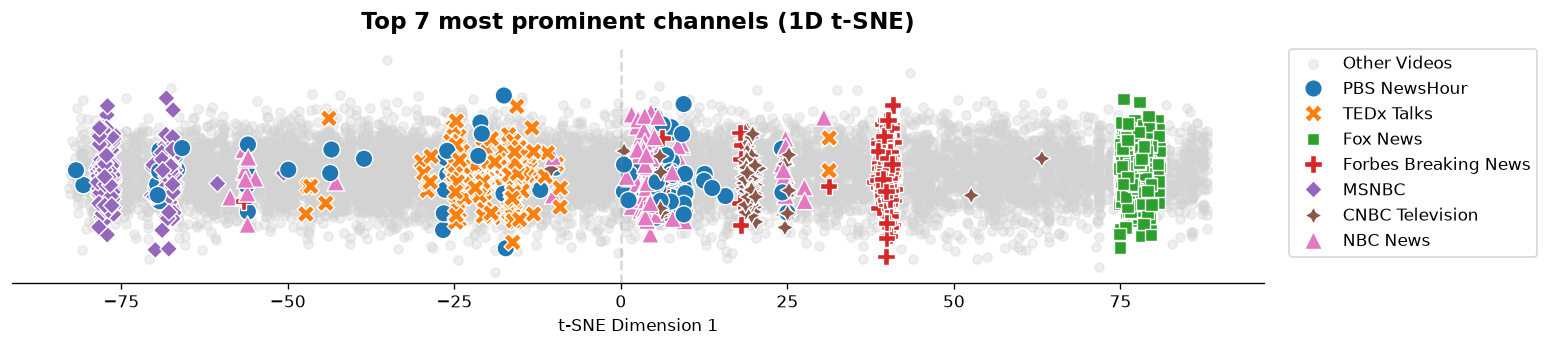

In [6]:
# 1. Assign the jitter directly to the main dataframe first
plot_df_sample["y_jitter"] = np.random.normal(loc=0, scale=0.02, size=len(plot_df_sample))

# 2. Identify top channels and create the subset (it now includes 'y_jitter')
top_channels = plot_df_sample["channel"].value_counts().head(7).index.tolist()
subset_df = plot_df_sample[plot_df_sample["channel"].isin(top_channels)]

# Use a shorter figure height for a 1D layout
fig, ax = plt.subplots(figsize=(13, 3))

# Background: all points in faint grey using the new jitter column
ax.scatter(
    plot_df_sample["tsne_1"],
    plot_df_sample["y_jitter"],
    color="lightgrey",
    alpha=0.35,
    s=30,
    label="Other Videos"
)

# Foreground: top channels using the string column name so Seaborn parses it correctly
import seaborn as sns
sns.scatterplot(
    data=subset_df,
    x="tsne_1",
    y="y_jitter",
    hue="channel",
    style="channel",
    s=110,
    ax=ax,
    palette="tab10"
)

ax.set_title(
    "Top 7 most prominent channels (1D t-SNE)",
    fontsize=14,
    fontweight="bold",
    pad=12
)
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("")

# Clean up the meaningless y-axis for a 1D plot
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

# Add origin line
ax.axvline(0, color="grey", linestyle="--", alpha=0.3)

# Legend placement
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)

plt.tight_layout()
plt.show()


### Plot D: 2D t-SNE Projection of Common Channels
Fit a 2-dimensional t-SNE manifold to uncover non-linear cluster structures and map how prominent news and commentary channels distribute across both the primary ideological dimension and orthogonal thematic / topic dimensions.


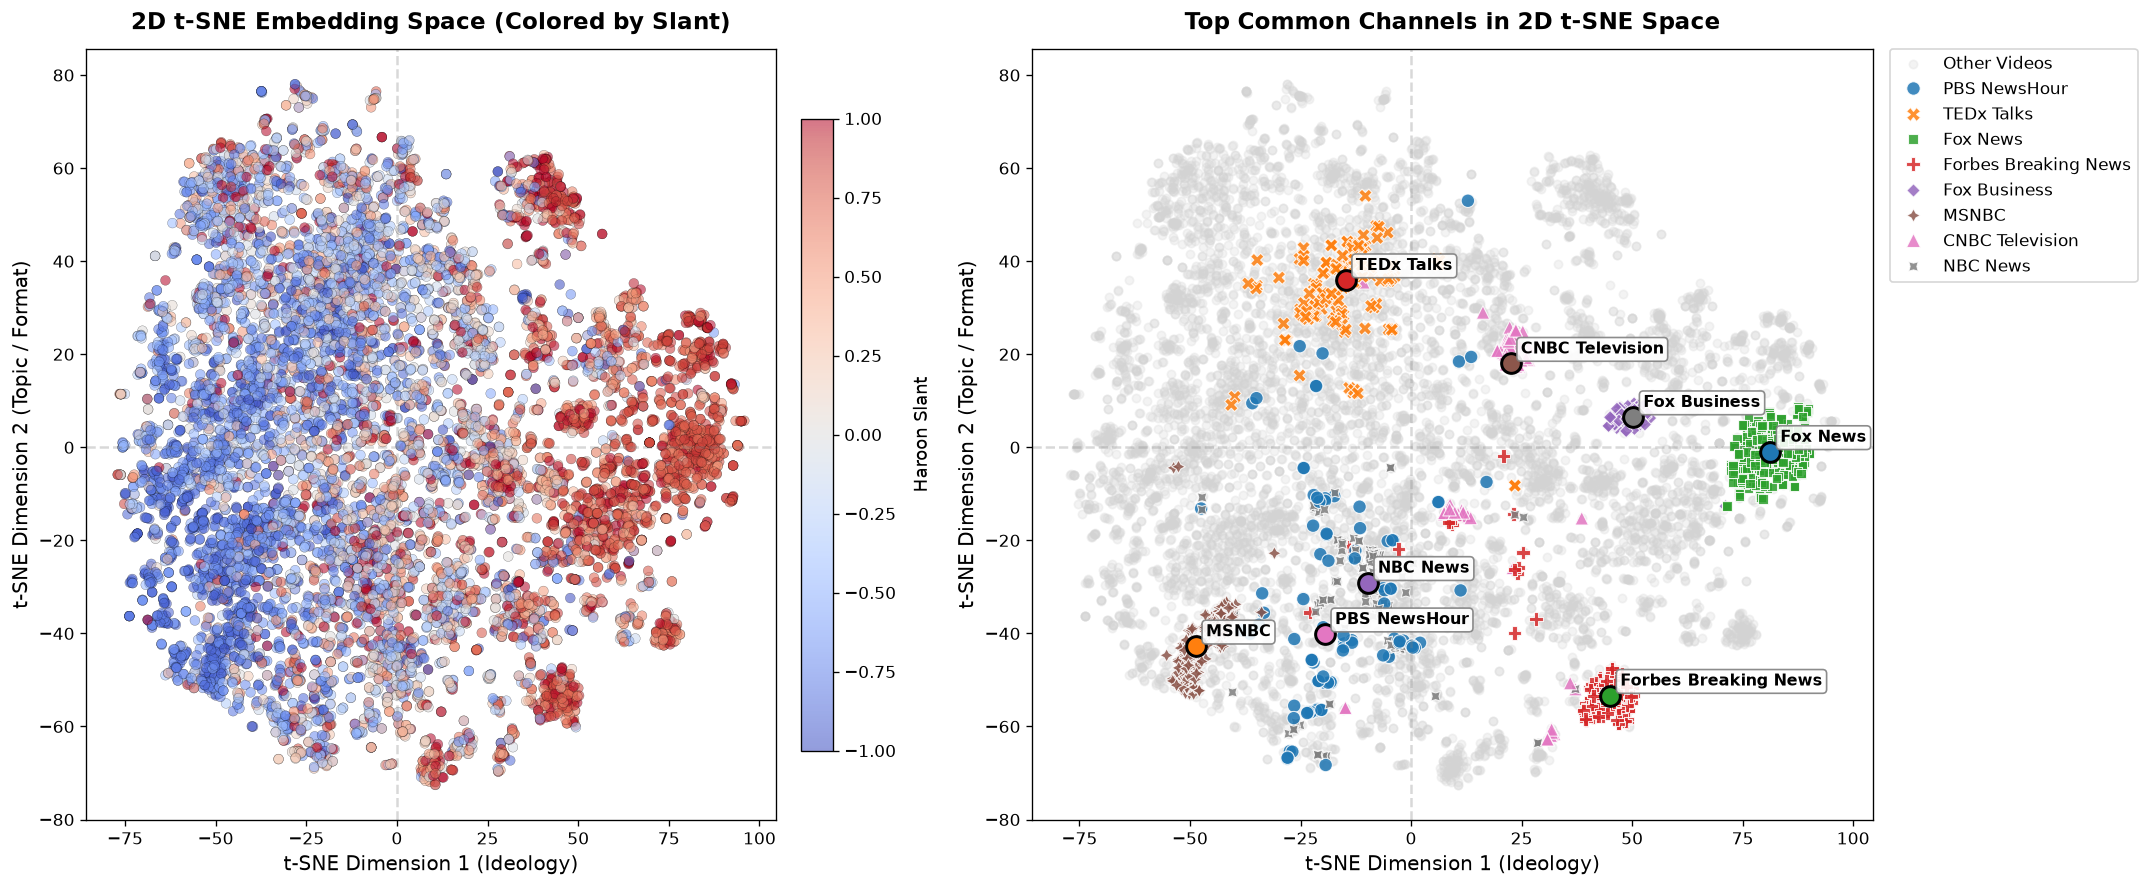

In [7]:
# Compute 2D t-SNE embeddings
tsne_2d = TSNE(n_components=2, random_state=SEED, perplexity=30, max_iter=1000, n_jobs=-1)
coords_2d = tsne_2d.fit_transform(embeddings)

# Orient Dim 1 so positive values align with conservative slant
raw_corr_dim1, _ = pearsonr(coords_2d[clean_mask, 0], plot_df.loc[clean_mask, "slant"])
if raw_corr_dim1 < 0:
    coords_2d[:, 0] = -coords_2d[:, 0]

plot_df["tsne_2d_1"] = coords_2d[:, 0]
plot_df["tsne_2d_2"] = coords_2d[:, 1]

# Identify top common channels
top_channels_2d = plot_df["channel"].value_counts().head(8).index.tolist()
subset_2d = plot_df[plot_df["channel"].isin(top_channels_2d)].copy()

# Plot 2D visualizations: Global Ideological Slant & Channel Clusters
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

# Panel 1: Ideological Slant in 2D t-SNE
sc1 = axes[0].scatter(
    plot_df["tsne_2d_1"],
    plot_df["tsne_2d_2"],
    c=plot_df["slant"],
    cmap="coolwarm",
    alpha=0.55,
    edgecolors="black",
    linewidth=0.2,
    s=35
)
cbar = plt.colorbar(sc1, ax=axes[0], shrink=0.82, pad=0.03)
cbar.set_label("Haroon Slant", fontsize=11, labelpad=10)
axes[0].set_title("2D t-SNE Embedding Space (Colored by Slant)", fontsize=14, fontweight="bold", pad=12)
axes[0].set_xlabel("t-SNE Dimension 1 (Ideology)", fontsize=12)
axes[0].set_ylabel("t-SNE Dimension 2 (Topic / Format)", fontsize=12)
axes[0].axvline(0, color="grey", linestyle="--", alpha=0.3)
axes[0].axhline(0, color="grey", linestyle="--", alpha=0.3)

# Panel 2: Highlight Common Channels
axes[1].scatter(
    plot_df["tsne_2d_1"],
    plot_df["tsne_2d_2"],
    color="lightgrey",
    alpha=0.25,
    s=25,
    label="Other Videos"
)

palette_2d = sns.color_palette("tab10", n_colors=len(top_channels_2d))
color_map_2d = dict(zip(top_channels_2d, palette_2d))

sns.scatterplot(
    data=subset_2d,
    x="tsne_2d_1",
    y="tsne_2d_2",
    hue="channel",
    style="channel",
    palette=palette_2d,
    s=65,
    alpha=0.85,
    ax=axes[1]
)

# Plot Centroids & Annotations
for ch in top_channels_2d:
    ch_pts = subset_2d[subset_2d["channel"] == ch]
    med_x = ch_pts["tsne_2d_1"].median()
    med_y = ch_pts["tsne_2d_2"].median()
    
    axes[1].scatter(
        med_x, med_y,
        s=140,
        color=color_map_2d[ch],
        edgecolor="black",
        linewidth=1.8,
        zorder=10
    )
    axes[1].annotate(
        ch,
        (med_x, med_y),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=9.5,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="grey", alpha=0.9),
        zorder=11
    )

axes[1].set_title("Top Common Channels in 2D t-SNE Space", fontsize=14, fontweight="bold", pad=12)
axes[1].set_xlabel("t-SNE Dimension 1 (Ideology)", fontsize=12)
axes[1].set_ylabel("t-SNE Dimension 2 (Topic / Format)", fontsize=12)
axes[1].axvline(0, color="grey", linestyle="--", alpha=0.3)
axes[1].axhline(0, color="grey", linestyle="--", alpha=0.3)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)

plt.tight_layout()
plt.show()


In [8]:
# Summary table of common channel coordinates in 2D t-SNE space
channel_summary = (
    subset_2d.groupby("channel")
    .agg(
        video_count=("title", "count"),
        median_tsne_1=("tsne_2d_1", "median"),
        median_tsne_2=("tsne_2d_2", "median"),
        mean_slant=("slant", "mean")
    )
    .sort_values("median_tsne_1")
    .reset_index()
)
display(channel_summary)


channel,video_count,median_tsne_1,median_tsne_2,mean_slant
MSNBC,211,-48.631313,-42.747932,-0.748014
PBS NewsHour,97,-19.461491,-40.141876,-0.279873
TEDx Talks,158,-14.744457,35.961906,-0.254924
NBC News,143,-9.757462,-29.096804,-0.048975
CNBC Television,102,22.570690,18.013935,0.025262
Forbes Breaking News,178,45.062855,-53.349960,0.723041
Fox Business,97,50.278999,6.522244,0.684609
Fox News,341,81.254402,-0.962540,0.748778


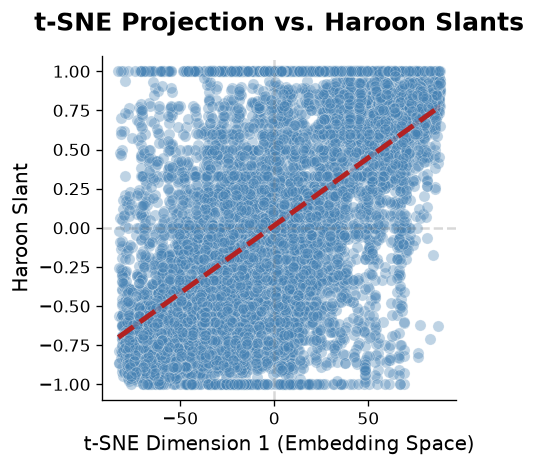

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 4))

sns.regplot(
    data=plot_df, 
    x="tsne_1", 
    y="slant",
    ax=ax,
    # Style the background data points
    scatter_kws={
        "alpha": 0.35,         
        "s": 45,               
        "color": "steelblue",  
        "edgecolor": "white",
        "linewidths": 0.4
    },
    # Style the regression line and confidence interval
    line_kws={
        "color": "firebrick",  
        "linewidth": 3.0,
        "linestyle": "--",     
        "zorder": 5            
    }
)

ax.set_title(
    "t-SNE Projection vs. Haroon Slants",
    fontsize=15, 
    fontweight="bold", 
    pad=15
)
ax.set_xlabel("t-SNE Dimension 1 (Embedding Space)", fontsize=12)
ax.set_ylabel("Haroon Slant", fontsize=12)

# Reference lines for the ideological center
ax.axhline(0, color="grey", linestyle="--", alpha=0.3, zorder=1)
ax.axvline(0, color="grey", linestyle="--", alpha=0.3, zorder=1)

# Remove harsh borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [10]:
from scipy.stats import pearsonr

# Drop nulls if any exist, as scipy cannot handle NaN values
clean_df = plot_df.dropna(subset=["tsne_1", "slant"])

corr, p_value = pearsonr(clean_df["tsne_1"], clean_df["slant"])

print(f"Pearson Correlation: {corr:.4f}")
print(f"P-value: {p_value:.4e}")


Pearson Correlation: 0.6241
P-value: 0.0000e+00


## Inspect Extreme Videos
Display the top videos with the lowest and highest t-SNE Dimension 1 values to inspect what semantic or ideological feature Dimension 1 represents.


In [11]:
print("=== Lowest t-SNE Dim 1 Values ===")
display(
    plot_df.sort_values("tsne_1")
    [["channel", "title", "slant", "political_saliency", "tsne_1"]]
    .head(5)
)

print("\n=== Highest t-SNE Dim 1 Values ===")
display(
    plot_df.sort_values("tsne_1", ascending=False)
    [["channel", "title", "slant", "political_saliency", "tsne_1"]]
    .head(5)
)


=== Lowest t-SNE Dim 1 Values ===


,channel,title,slant,political_saliency,tsne_1
9152,Artur Kalbarczyk,"Powell, Trump, Malone, Q & A",1.000000,0.9,-82.859856
8996,TeleSUR English,"Mike Pompeo About CIA : We lied, We cheated, We stole",-0.018182,1.0,-82.675873
4737,Glenn Kirschner,Bill Barr's Shocking Atlantic Interview Reveals Incriminating Evidence of Trump's Corrupt Intent,-0.862200,1.0,-82.661049
7771,The Dean Obeidallah Show,Former prosecutor Glenn Kirschner: Trump's actions on Covid-19 is Manslaughter,-0.862070,1.0,-82.569878
3429,Anon ymous,Kellyanne Conway -Truth About Trump,-0.790090,1.0,-82.496162



=== Highest t-SNE Dim 1 Values ===


,channel,title,slant,political_saliency,tsne_1
8653,Glenn Beck,"10 steps to protect YOUR money from MASSIVE, coming changes",0.64894,1.0,88.066109
2902,Glenn Beck,The Oval: The Supreme Court,1.00000,0.8,88.047577
3230,Glenn Beck,Coronavirus & THE NEXT RECESSION? Loans from the Federal Reserve hint big banks are in BIG trouble,0.92222,0.8,88.038918
1826,Glenn Beck,Glenn CALLS OUT companies working with China DESPITE horrific concentration camps,0.91083,1.0,88.007858
4395,Glenn Beck,Glenn: Evil is washing over the world right now,0.87037,1.0,87.983345


## Comparison to human labelers


In [12]:
human_labels = pd.read_pickle(DATA_DIR / "human_labels" / "human_labels.pkl")
vid_metadata = pd.read_parquet(DATA_DIR / "human_labels" / "vid_metadata.parquet")

# Retain base columns to avoid duplicate score columns on re-merging
base_cols = ["unique_ID", "category_name", "human_label", "coder_id", "label_timestamp", "top_video_id", "bottom_video_id"]
human_labels = human_labels[[c for c in base_cols if c in human_labels.columns]].copy()

human_labels.head()


,unique_ID,category_name,human_label,coder_id,label_timestamp,top_video_id,bottom_video_id
0,1025,Indicate which video is more liberal,bot,8,1630462269,5HK1hFUD_d4,QPVA8HH7l1w
1,1112,Indicate which video is more liberal,top,8,1630462309,npAKW_HPnq8,AK4_ogsh0Po
2,1029,Indicate which video is more liberal,bot,8,1630467371,Ib1nTc7859Y,_TgcOISrlqE
3,1061,Indicate which video is more liberal,bot,8,1630467386,KC-JiXnQSUA,JkxW7ecWl-o
4,1070,Indicate which video is more liberal,bot,8,1630467421,SvjTeuSKTW0,iEWqEtnLLEo


In [13]:
vid_metadata.head()


id                                               text
0  vipqI7SCgjA  Channel: The Damage Report \n Title: Trump Get...
1  q5Gr9SQmkfc  Channel: Marfoogle News \n Title: THEY DONT WA...
2  fyF1pepEpDE  Channel: The Jimmy Dore Show \n Title: Justice...
3  QPVA8HH7l1w  Channel: The Damage Report \n Title: Bernie SL...
4  AK4_ogsh0Po  Channel: VICE News \n Title: This Private Scho...

In [14]:
human_labels_merged = human_labels.merge(
    vid_metadata.rename(columns={"id": "top_video_id", "text": "top_video_text"}), 
    on="top_video_id", 
    how="left"
)

human_labels_merged = human_labels_merged.merge(
    vid_metadata.rename(columns={"id": "bottom_video_id", "text": "bottom_video_text"}), 
    on="bottom_video_id", 
    how="left"
)


In [15]:
human_labels_merged.head()


,unique_ID,category_name,human_label,coder_id,label_timestamp,top_video_id,bottom_video_id,top_video_text,bottom_video_text
0,1025,Indicate which video is more liberal,bot,8,1630462269,5HK1hFUD_d4,QPVA8HH7l1w,"Channel: Rob Trent \n Title: Social justice warriors are racists who hate free speech \n This exchange highlights three traits that are prevalent amongst social justice warriors; \n\n1) They don't believe in equality. \n\nThe film maker's free speech is immediately disqualified and the woman attempts to no platform him because he doesn't agree with her politically and is a white man.\n\n2) They don't believe in free speech.\n\nThe woman tries to impose her own authoritarian code of conduct on the man in order to silence his First Amendment rights.\n\n3) They're racist.\n\nThe white woman rushes to the aid of the Mexican woman, presuming that she is unable to defend her political ideas on her own because she is a minority. This is the bigotry of low expectations. \n\nFULL VIDEO by Rebel Pundit: https://www.youtube.com/watch?v=LIjljucvBI4 \n Tags: ['social justice warriors', 'anti-trump', 'chicago', 'sjw', 'leftists', 'bernie sanders', 'moveon']","Channel: The Damage Report \n Title: Bernie SLAMS Lazy Republicans \n Bernie Sanders and Andrew Yang slam Senate Republicans after they take vacation, abandoning America during a crisis. John Iadarola and Brett Erlich break it down on The Damage Report. Follow The Damage Report on Facebook: https://www.facebook.com/TheDamageReportTYT/\n\nHelp build the Home of the Progressives http://tyt.com/JOIN\n\nSubscribe to The Damage Report YouTube channel: https://www.youtube.com/thedamagereport?sub_confirmation=1\n\nFollow The Damage Report on Twitter: https://twitter.com/TheDamageReport\n\nRead more here: https://www.cnbc.com/2020/08/13/where-stimulus-talks-stand-now-that-senate-has-adjourned-for-august.html\n\n""The Senate is officially adjourned through Labor Day despite not coming to an agreement on its next coronavirus stimulus package.\n\nCongress and the White House have spent the past few weeks debating what to include in the package, but have been unable to come to an agreement. One of the biggest sticking points: Jobless benefits. Democrats want a continuation of the enhanced unemployment payment of $600 per week, while Republicans say that amount is too high. Democrats are also pushing for more than $900 billion for state and municipal aid, and $60 billion in food assistance, far higher than what Republicans have proposed.\n\nHouse Speaker Nancy Pelosi (D-Calif.) said the two sides would not strike a deal until Republicans added $1 trillion in aid to their bill. \n\nThat means a deal could be weeks away. Meanwhile, around 28 million Americans remain unemployed and many of the relief provisions from the first stimulus package have dried up. President Donald Trump has issued four executive orders to address some of the issues, but experts remain unconvinced that they will be efficient in helping vulnerable households.""\n\n#TheDamageReport #JohnIadarola #TheYoungTurks \n Tags: ['200814__DR02generalStrikeGenX', 'News', 'Politics', 'breaking news', 'The Damage Report', 'TDR', 'John Iadarola', 'Brett Erlich', 'The Young Turks', 'tyt', 'progressive news', 'progressive media', 'progressives', 'mitch mcconnell', 'mcconnell', 'strike', 'congress', 'senate', 'house of representatives', 'bernie sanders', 'andrew yang', 'general strike', 'relief bill', 'stimulus bill', 'stimulus', 'congressional', 'house', 'coronavirus pandemic', 'coronavirus', 'unemployment', 'stimulus checks', 'relief package', 'relieg', 'recession', 'us economy', 'us workers']"
1,1112,Indicate which video is more liberal,top,8,1630462309,npAKW_HPnq8,AK4_ogsh0Po,"Channel: The Damage Report \n Title: AOC Officially Endorses Bernie For President \n Rep. Alexandria Ocasio-Cortez endorses Bernie Sanders for President. John Iadarola and Brooke Thomas break it down on The Damage Report. Follow The Damage Report on Facebook: ht

Load model


In [16]:
from sentence_transformers import SentenceTransformer
import torch

model_dir = MODEL_DIR / "political-embedder-small"
device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")

# Identify latest checkpoint directory
checkpoints = sorted(
    [d for d in model_dir.glob("checkpoint-*") if d.is_dir()],
    key=lambda p: int(p.name.split("-")[1]) if p.name.split("-")[1].isdigit() else 0
)
model_path = checkpoints[-1] if checkpoints else model_dir
print(f"Loading checkpoint from: {model_path}")

model = SentenceTransformer(str(model_path), device=device)
print(f"Model successfully loaded on {device}. Embedding dimension: {model.get_sentence_embedding_dimension()}")


Loading checkpoint from: /Users/gustavidunsloth/Documents/Data Science/youtube-ideology-classifier/models/political-embedder-small/checkpoint-2653
Model successfully loaded on mps. Embedding dimension: 768


In [17]:
# Compute embeddings for unique videos to ensure consistent coordinates and efficiency
unique_vids = vid_metadata.dropna(subset=["text"]).copy()
vid_texts = unique_vids["text"].astype(str).tolist()

vid_embeddings = model.encode(
    vid_texts,
    batch_size=128,
    show_progress_bar=True,
    normalize_embeddings=True
)

print(f"Encoded {len(vid_embeddings)} unique videos.")


Encoded 2382 unique videos.


In [18]:
# Project video embeddings into 1D with t-SNE
tsne_eval = TSNE(n_components=1, random_state=42, perplexity=30)
scores_1d = tsne_eval.fit_transform(vid_embeddings).flatten()

# Map scores to video IDs (invert sign so positive values align with conservative ideology)
id_to_score = dict(zip(unique_vids["id"], -scores_1d))


In [19]:
# Map 1D t-SNE ideological scores to pairwise comparison dataframe
human_labels_merged["top_video_score"] = human_labels_merged["top_video_id"].map(id_to_score)
human_labels_merged["bottom_video_score"] = human_labels_merged["bottom_video_id"].map(id_to_score)


In [20]:
human_labels_merged[["top_video_id", "bottom_video_id", "top_video_score", "bottom_video_score"]].head()


,top_video_id,bottom_video_id,top_video_score,bottom_video_score
0,5HK1hFUD_d4,QPVA8HH7l1w,24.071459,-42.504246
1,npAKW_HPnq8,AK4_ogsh0Po,-28.002932,-33.482277
2,Ib1nTc7859Y,_TgcOISrlqE,28.618223,-44.469276
3,KC-JiXnQSUA,JkxW7ecWl-o,-54.094078,-49.323326
4,SvjTeuSKTW0,iEWqEtnLLEo,33.078995,-26.798120


In [21]:
def label_pred(row):
    if row["category_name"] == "Indicate which video is more conservative":
        if row["top_video_score"] > row["bottom_video_score"]: return "top"
        else: return "bot"
    else:
        if row["top_video_score"] > row["bottom_video_score"]: return "bot"
        else: return "top"

human_labels_merged["pred_label"] = human_labels_merged.apply(label_pred, axis=1)
human_labels_merged["agree"] = human_labels_merged.apply(lambda row: True if row["pred_label"] == row["human_label"] else False, axis=1)
human_labels_merged["dist"] = human_labels_merged.apply(lambda row: abs(row["top_video_score"] - row["bottom_video_score"]), axis=1)


In [22]:
from sklearn.metrics import classification_report

print(classification_report(human_labels_merged["human_label"], human_labels_merged["pred_label"]))


              precision    recall  f1-score   support

         bot       0.68      0.67      0.68      2050
         top       0.69      0.70      0.69      2102

    accuracy                           0.68      4152
   macro avg       0.68      0.68      0.68      4152
weighted avg       0.68      0.68      0.68      4152



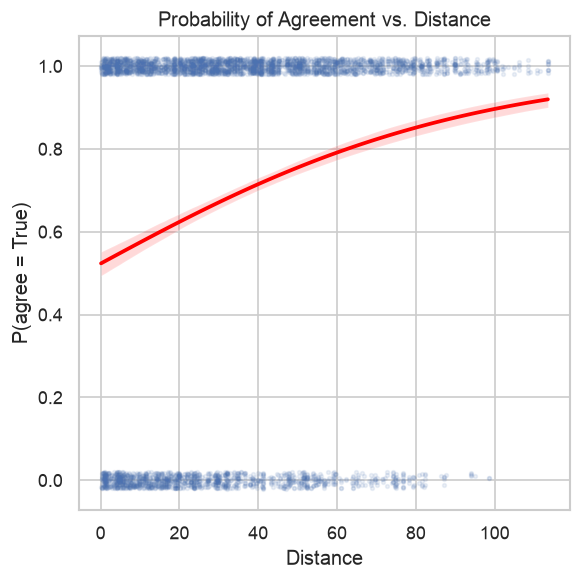

In [23]:
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.figure(figsize=(5, 5))
sns.set_theme(style="whitegrid")

sns.regplot(
    data=human_labels_merged,
    x="dist",
    y="agree",
    logistic=True,
    ci=95,
    scatter_kws={"s": 5, "alpha": 0.1},
    line_kws={"color": "red"},
    y_jitter=0.02,
)

plt.title("Probability of Agreement vs. Distance")
plt.ylabel("P(agree = True)")
plt.xlabel("Distance")
plt.show()
